# Alpha sweep post-analysis

This notebook embeds the observed data and standalone plotting code. Rerun the code cell to reproduce the figures.

## Model and experiment setup

We trained a 29,915,520-parameter decoder-only language model with 6 layers, 6 attention heads, width 384, a 4x-width GELU MLP, RMSNorm, rotary positions, tied input/output embeddings, GPT-2 tokenization (50,257-token vocabulary), and sequence length 1,024. Data came from `kjj0/fineweb10B-gpt2`: downloaded training shards `fineweb_train_000001.bin` through `fineweb_train_000033.bin` contain 3.3B tokens; validation uses `fineweb_val_000000.bin` (100M tokens available), always evaluating its first 1,048,576 tokens every 25 steps and at the final step. Each trial starts from scratch and reads sorted shards sequentially from the beginning, without shuffling. Global batch size is 512 sequences (524,288 tokens/step), using microbatches of 8 and 64 accumulation steps on one GPU. Matrix parameters use fixed-alpha Muon (learning rate 0.00036, EMA momentum 0.95); tied embeddings/output use AdamW (learning rate 0.0036, betas 0.9/0.95). Weight decay and warmup are zero; learning rates decay linearly over the last 10 steps. BF16 autocast and compiled PyTorch ran on an RTX PRO 4000 Blackwell with Python 3.12.3 and PyTorch 2.8.0+cu128 (PyTorch CUDA 12.8). Round 1 screened 13 alphas from 0 to 3 at spacing 0.25 for 100 steps; round 2 tested 13 merged candidates from 0.75 to 1.5 at spacing 0.0625 for 100 steps; both used seed 0. Round 3 tested 7 candidates from 0.9375 to 1.125 at spacing 0.03125 for 500 steps per seed, seeds 0 and 1. Selection minimizes mean final validation loss across these two seeds; error bars use population standard deviation. Per-trial training budgets are 52,428,800 or 262,144,000 tokens, not full epochs. Source is preserved in experiment commit `1307c00ade72a54bb706b259dd8fd55b0d5ffe33`; the deployed trainer SHA256 was `fa7b76d7976c4baab368cbae1b8e33469c568e9ef7bc52801eccb57fd5192615`. Dataset revision/checksums and a complete dependency lockfile were not captured, and CUDA execution is not guaranteed bitwise deterministic; these limit exact reproducibility.

Equivalent explicit controller command, from the repository root on the pod (the historical launch used defaults for some of these flags):

```sh
/workspace/venv/bin/python -u alpha_sweep/train_gpt2_cond_muon.py --sweep \
  --alpha-grid 0 0.25 0.5 0.75 1 1.25 1.5 1.75 2 2.25 2.5 2.75 3 \
  --screen-steps 100 --refine-steps 100 --finalist-steps 500 \
  --finalist-seeds 0 1 --top-k 2 --seed 0 --device-batch-size 8 \
  --val-tokens 1048576 --val-loss-every 25 --save-every 0 \
  --warmdown-iters 10 --output-dir /workspace/alpha-sweep-3-rounds
```

The output directory must be new. For a future autonomous run, use `alpha_sweep/launch.sh` with a fresh path: it runs training, analysis, verified publication and pod stop inside tmux, skipping separate preflight and smoke runs.

## Theory and alpha formalism

For matrix gradient $G_t$, define EMA momentum $M_t=\beta M_{t-1}+(1-\beta)G_t$ with $\beta=0.95$, and $X=M_t/\max(\lVert M_t\rVert_F,\epsilon)$ with $\epsilon=10^{-7}$. Transpose tall matrices first; fused Q/K/V momentum matrices are split into square blocks and transformed separately. For each block, fixed $\alpha\geq0$ controls the spectral transform, followed by Frobenius rescaling and a learning-rate update (transpose back when needed):

$$
Y_\alpha=(XX^\top+\delta^2 I)^{-\alpha/2}X,\qquad
\Delta_\alpha=\frac{\sqrt{r}\,Y_\alpha}{\max(\lVert Y_\alpha\rVert_F,\epsilon)},\qquad
W_{t+1}=W_t-\eta\Delta_\alpha,
$$

where $\delta=0.01$, $r=\min(m,n)$ for an $m\times n$ block, and $\eta$ is the scheduled Muon learning rate. If $X=U\operatorname{diag}(\sigma_i)V^\top$, its singular values before output rescaling obey $\sigma_i\mapsto\sigma_i(\sigma_i^2+\delta^2)^{-\alpha/2}$. Thus $\alpha$ controls spectral shape, not step size: $\alpha=0$ preserves the momentum direction; $\alpha=1$ approximates the polar factor for $\sigma_i\gg\delta$; and $\alpha>1$ favors smaller above-floor singular values and can amplify noise. Only in the unregularized positive-spectrum idealization does the map simplify to $\sigma_i^{1-\alpha}$, giving $\kappa(Y_\alpha)=\kappa(X)^{|1-\alpha|}$. This condition-number identity is not exact for the regularized implementation: near zero, the floor bounds the multiplier by $\delta^{-\alpha}$ and zero singular values stay zero. The code evaluates the regularized transform through a Gram eigendecomposition, not a polynomial inverse-power approximation. The sweep holds $\alpha$ constant within each trial, unlike the original moment-adaptive rule; it identifies only the best tested value at these budgets. In particular, the winning $\alpha=0.9375$ lies at the lower edge of the round 3 grid, so values below that edge at 500 steps remain an important untested follow-up.

The sweep selected $\alpha=0.9375$ by minimizing the mean final validation loss, using objective 'mean final validation loss across round 3 seeds' and round 3 seeds [0, 1]; its observed mean was 5.15316 with population standard deviation 0.00593162, and the next-best complete tested alpha was 0.0197852 higher. Budgets were 100 round 1 steps and 100 round 2 steps for seed 0, then 500 round 3 steps; each run used 1048576 validation tokens. The configured spectral floor was 0.01.

Run status was completed. Across all rounds, 0 required trial record(s) diverged, 0 required result(s) were missing, and 0 alpha-round point(s) were excluded; excluded points are not plotted or used in aggregates. Results are limited to the tested grid and available seeds, budgets differ by round, and the best tested alpha is not evidence of a global optimum.


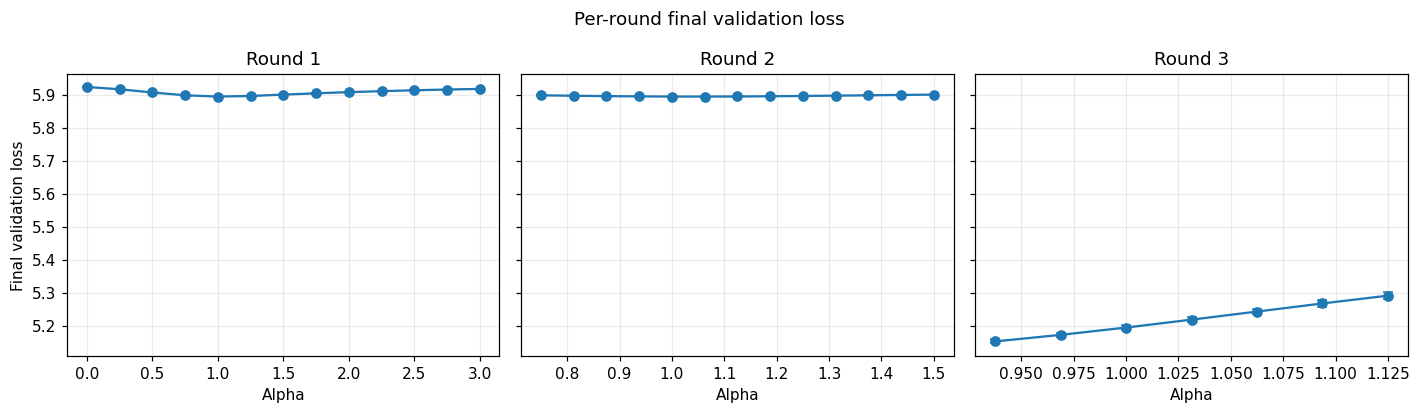

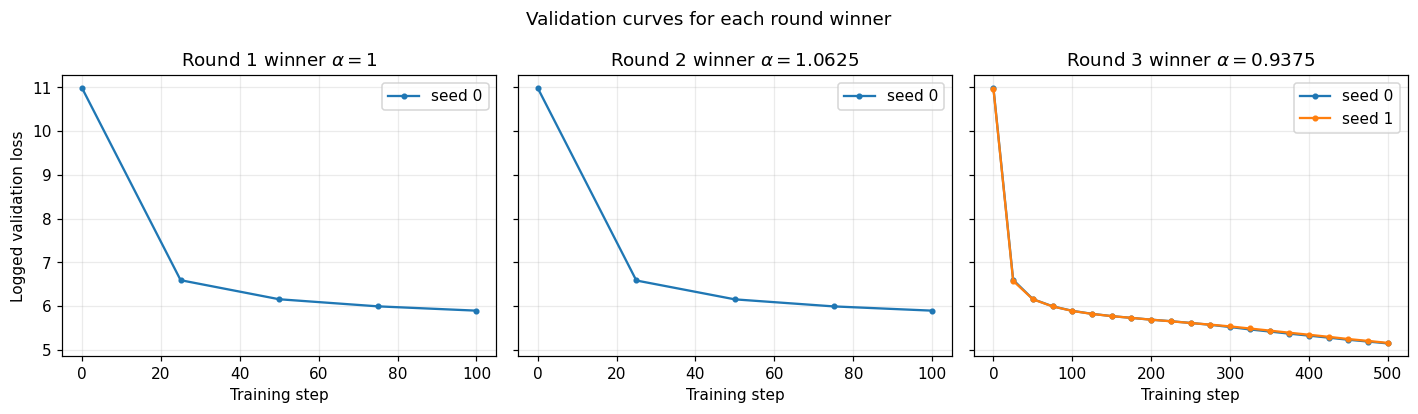

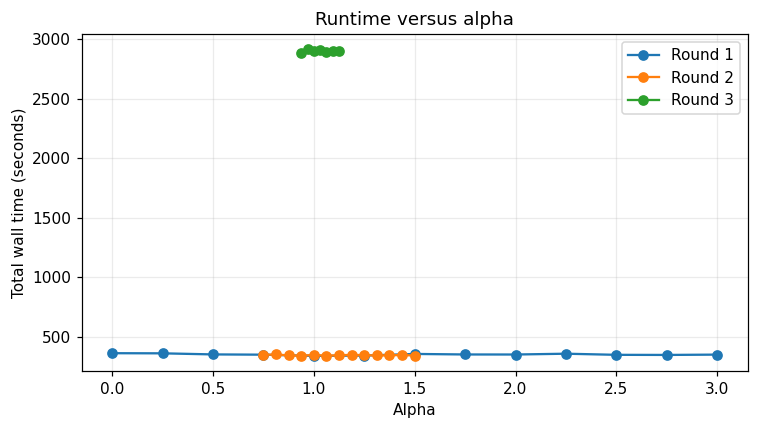

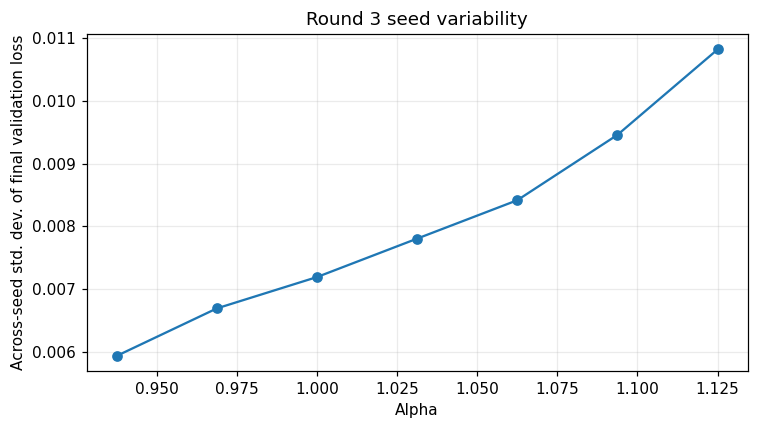

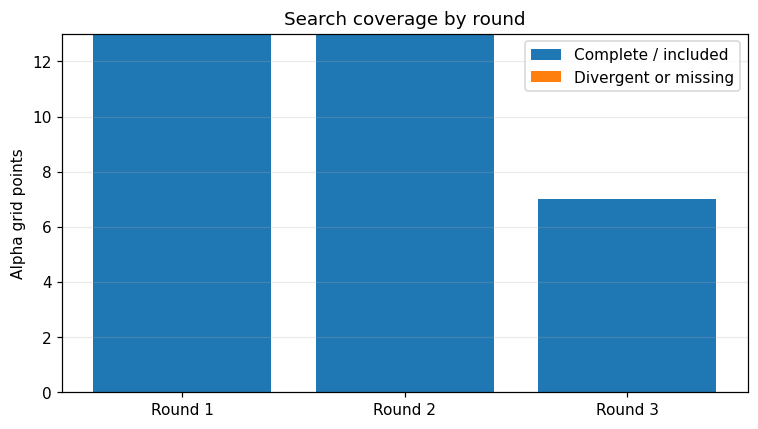

In [1]:
DATA = {'config': {'objective': 'mean final validation loss across confirmation seeds', 'screening_seed': 0, 'finalist_seeds': [0, 1], 'screen_steps': 100, 'refine_steps': 100, 'finalist_steps': 500, 'val_tokens': 1048576, 'spectral_floor': 0.01}, 'rounds': {'screening': {'grid': [0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5, 2.75, 3.0], 'points': [{'alpha': 0.0, 'mean': 5.9247355461120605, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.9247355461120605], 'runtime_seconds': 363.629986367072}, {'alpha': 0.25, 'mean': 5.91782808303833, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.91782808303833], 'runtime_seconds': 362.5588522810722}, {'alpha': 0.5, 'mean': 5.908141613006592, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.908141613006592], 'runtime_seconds': 353.43120409199037}, {'alpha': 0.75, 'mean': 5.899562358856201, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.899562358856201], 'runtime_seconds': 351.23728044494055}, {'alpha': 1.0, 'mean': 5.895757675170898, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.895757675170898], 'runtime_seconds': 341.1841875180835}, {'alpha': 1.25, 'mean': 5.897477149963379, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.897477149963379], 'runtime_seconds': 343.6579760409659}, {'alpha': 1.5, 'mean': 5.901605129241943, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.901605129241943], 'runtime_seconds': 357.4187652639812}, {'alpha': 1.75, 'mean': 5.905591011047363, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.905591011047363], 'runtime_seconds': 352.99215349392034}, {'alpha': 2.0, 'mean': 5.909088134765625, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.909088134765625], 'runtime_seconds': 352.60239521902986}, {'alpha': 2.25, 'mean': 5.912106990814209, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.912106990814209], 'runtime_seconds': 359.3599286369281}, {'alpha': 2.5, 'mean': 5.9147257804870605, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.9147257804870605], 'runtime_seconds': 349.99643745995127}, {'alpha': 2.75, 'mean': 5.917013645172119, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.917013645172119], 'runtime_seconds': 349.0609823790146}, {'alpha': 3.0, 'mean': 5.918900012969971, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.918900012969971], 'runtime_seconds': 351.7685662400909}], 'coverage': [{'alpha': 0.0, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 0.25, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 0.5, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 0.75, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 1.0, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 1.25, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 1.5, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 1.75, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 2.0, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 2.25, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 2.5, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 2.75, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 3.0, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}], 'excluded': []}, 'refinement': {'grid': [0.75, 0.8125, 0.875, 0.9375, 1.0, 1.0625, 1.125, 1.1875, 1.25, 1.3125, 1.375, 1.4375, 1.5], 'points': [{'alpha': 0.75, 'mean': 5.899543285369873, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.899543285369873], 'runtime_seconds': 349.7235917740036}, {'alpha': 0.8125, 'mean': 5.898110389709473, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.898110389709473], 'runtime_seconds': 352.9119184559677}, {'alpha': 0.875, 'mean': 5.8970112800598145, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.8970112800598145], 'runtime_seconds': 344.9291631890228}, {'alpha': 0.9375, 'mean': 5.896175384521484, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.896175384521484], 'runtime_seconds': 342.97243736998644}, {'alpha': 1.0, 'mean': 5.895737171173096, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.895737171173096], 'runtime_seconds': 348.823774221004}, {'alpha': 1.0625, 'mean': 5.89568567276001, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.89568567276001], 'runtime_seconds': 342.92415819398593}, {'alpha': 1.125, 'mean': 5.895960330963135, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.895960330963135], 'runtime_seconds': 346.5948701039888}, {'alpha': 1.1875, 'mean': 5.896603584289551, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.896603584289551], 'runtime_seconds': 349.3595409649424}, {'alpha': 1.25, 'mean': 5.89748477935791, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.89748477935791], 'runtime_seconds': 347.19917749101296}, {'alpha': 1.3125, 'mean': 5.898453235626221, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.898453235626221], 'runtime_seconds': 344.5778963280609}, {'alpha': 1.375, 'mean': 5.899532318115234, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.899532318115234], 'runtime_seconds': 346.084358875989}, {'alpha': 1.4375, 'mean': 5.90057373046875, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.90057373046875], 'runtime_seconds': 348.2495220369892}, {'alpha': 1.5, 'mean': 5.901626110076904, 'std': 0.0, 'n': 1, 'required': 1, 'losses': [5.901626110076904], 'runtime_seconds': 343.83804551209323}], 'coverage': [{'alpha': 0.75, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 0.8125, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 0.875, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 0.9375, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 1.0, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 1.0625, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 1.125, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 1.1875, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 1.25, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 1.3125, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 1.375, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 1.4375, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 1.5, 'required': 1, 'completed': 1, 'diverged': 0, 'missing': 0, 'eligible': True}], 'excluded': []}, 'confirmation': {'grid': [0.9375, 0.96875, 1.0, 1.03125, 1.0625, 1.09375, 1.125], 'points': [{'alpha': 0.9375, 'mean': 5.153156042098999, 'std': 0.0059316158294677734, 'n': 2, 'required': 2, 'losses': [5.147224426269531, 5.159087657928467], 'runtime_seconds': 2886.865155030857}, {'alpha': 0.96875, 'mean': 5.172941207885742, 'std': 0.0066890716552734375, 'n': 2, 'required': 2, 'losses': [5.166252136230469, 5.179630279541016], 'runtime_seconds': 2914.509530003066}, {'alpha': 1.0, 'mean': 5.195202112197876, 'std': 0.007189035415649414, 'n': 2, 'required': 2, 'losses': [5.188013076782227, 5.202391147613525], 'runtime_seconds': 2905.9465135090286}, {'alpha': 1.03125, 'mean': 5.219141244888306, 'std': 0.007802248001098633, 'n': 2, 'required': 2, 'losses': [5.211338996887207, 5.226943492889404], 'runtime_seconds': 2911.509382383083}, {'alpha': 1.0625, 'mean': 5.243711233139038, 'std': 0.008414506912231445, 'n': 2, 'required': 2, 'losses': [5.235296726226807, 5.2521257400512695], 'runtime_seconds': 2893.8821469969116}, {'alpha': 1.09375, 'mean': 5.268323659896851, 'std': 0.009456872940063477, 'n': 2, 'required': 2, 'losses': [5.258866786956787, 5.277780532836914], 'runtime_seconds': 2905.017258898006}, {'alpha': 1.125, 'mean': 5.292007684707642, 'std': 0.010819196701049805, 'n': 2, 'required': 2, 'losses': [5.281188488006592, 5.302826881408691], 'runtime_seconds': 2901.677766968962}], 'coverage': [{'alpha': 0.9375, 'required': 2, 'completed': 2, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 0.96875, 'required': 2, 'completed': 2, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 1.0, 'required': 2, 'completed': 2, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 1.03125, 'required': 2, 'completed': 2, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 1.0625, 'required': 2, 'completed': 2, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 1.09375, 'required': 2, 'completed': 2, 'diverged': 0, 'missing': 0, 'eligible': True}, {'alpha': 1.125, 'required': 2, 'completed': 2, 'diverged': 0, 'missing': 0, 'eligible': True}], 'excluded': []}}, 'winners': {'screening': {'alpha': 1.0, 'mean': 5.895757675170898, 'curves': [{'seed': 0, 'points': [{'step': 0, 'val_loss': 10.9807}, {'step': 25, 'val_loss': 6.5914}, {'step': 50, 'val_loss': 6.1559}, {'step': 75, 'val_loss': 5.9941}, {'step': 100, 'val_loss': 5.8958}]}], 'expected_seeds': [0]}, 'refinement': {'alpha': 1.0625, 'mean': 5.89568567276001, 'curves': [{'seed': 0, 'points': [{'step': 0, 'val_loss': 10.9807}, {'step': 25, 'val_loss': 6.5847}, {'step': 50, 'val_loss': 6.1535}, {'step': 75, 'val_loss': 5.993}, {'step': 100, 'val_loss': 5.8957}]}], 'expected_seeds': [0]}, 'confirmation': {'alpha': 0.9375, 'mean': 5.153156042098999, 'curves': [{'seed': 0, 'points': [{'step': 0, 'val_loss': 10.9807}, {'step': 25, 'val_loss': 6.5992}, {'step': 50, 'val_loss': 6.1588}, {'step': 75, 'val_loss': 5.9957}, {'step': 100, 'val_loss': 5.8918}, {'step': 125, 'val_loss': 5.8232}, {'step': 150, 'val_loss': 5.7707}, {'step': 175, 'val_loss': 5.7305}, {'step': 200, 'val_loss': 5.6901}, {'step': 225, 'val_loss': 5.6546}, {'step': 250, 'val_loss': 5.615}, {'step': 275, 'val_loss': 5.5723}, {'step': 300, 'val_loss': 5.5219}, {'step': 325, 'val_loss': 5.4669}, {'step': 350, 'val_loss': 5.4196}, {'step': 375, 'val_loss': 5.3706}, {'step': 400, 'val_loss': 5.3252}, {'step': 425, 'val_loss': 5.2792}, {'step': 450, 'val_loss': 5.2309}, {'step': 475, 'val_loss': 5.1899}, {'step': 500, 'val_loss': 5.1472}]}, {'seed': 1, 'points': [{'step': 0, 'val_loss': 10.9634}, {'step': 25, 'val_loss': 6.5758}, {'step': 50, 'val_loss': 6.1561}, {'step': 75, 'val_loss': 5.992}, {'step': 100, 'val_loss': 5.8895}, {'step': 125, 'val_loss': 5.8213}, {'step': 150, 'val_loss': 5.7704}, {'step': 175, 'val_loss': 5.731}, {'step': 200, 'val_loss': 5.689}, {'step': 225, 'val_loss': 5.6529}, {'step': 250, 'val_loss': 5.6134}, {'step': 275, 'val_loss': 5.5767}, {'step': 300, 'val_loss': 5.5357}, {'step': 325, 'val_loss': 5.4882}, {'step': 350, 'val_loss': 5.4408}, {'step': 375, 'val_loss': 5.392}, {'step': 400, 'val_loss': 5.3453}, {'step': 425, 'val_loss': 5.2977}, {'step': 450, 'val_loss': 5.2472}, {'step': 475, 'val_loss': 5.2041}, {'step': 500, 'val_loss': 5.1591}]}], 'expected_seeds': [0, 1]}}, 'best': {'alpha': 0.9375, 'mean': 5.153156042098999, 'std': 0.0059316158294677734, 'seed_losses': [5.147224426269531, 5.159087657928467], 'gap': 0.019785165786743164, 'next_mean': 5.172941207885742}, 'counts': {'diverged_records': 0, 'missing_records': 0, 'excluded_alpha_rounds': 0}, 'warnings': [], 'run_status': 'completed'}

import matplotlib.pyplot as plt

# DATA is embedded by post_analysis.py so this notebook can be rerun offline.
STAGE_ORDER = ("screening", "refinement", "confirmation")
STAGE_LABELS = {"screening": "Round 1", "refinement": "Round 2",
                "confirmation": "Round 3"}

# 1. Final validation loss against alpha, with across-seed standard deviations.
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, stage in zip(axes, STAGE_ORDER):
    points = DATA["rounds"][stage]["points"]
    if points:
        ax.errorbar([p["alpha"] for p in points], [p["mean"] for p in points],
                    yerr=[p["std"] for p in points], marker="o", capsize=3)
    else:
        ax.text(0.5, 0.5, "No complete alpha results", ha="center", va="center",
                transform=ax.transAxes)
    ax.set(title=STAGE_LABELS[stage], xlabel="Alpha")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Final validation loss")
fig.suptitle("Per-round final validation loss")
fig.tight_layout()
plt.show()
plt.close(fig)

# 2. Logged validation curves for each round's best complete alpha; absent
# logs are omitted, never interpolated or synthesized.
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, stage in zip(axes, STAGE_ORDER):
    winner = DATA["winners"][stage]
    if winner["alpha"] is None:
        ax.text(0.5, 0.5, "No complete alpha results", ha="center", va="center",
                transform=ax.transAxes)
    else:
        for curve in winner["curves"]:
            pts = curve["points"]
            ax.plot([p["step"] for p in pts], [p["val_loss"] for p in pts],
                    marker=".", label="seed {}".format(curve["seed"]))
        if winner["curves"]:
            ax.legend()
        else:
            ax.text(0.5, 0.5, "No logged curve available", ha="center", va="center",
                    transform=ax.transAxes)
        ax.set_title(r"{} winner $\alpha={:g}$".format(STAGE_LABELS[stage], winner["alpha"]))
    ax.set_xlabel("Training step")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Logged validation loss")
fig.suptitle("Validation curves for each round winner")
fig.tight_layout()
plt.show()
plt.close(fig)

# 3. Total observed runtime per alpha, only when every required seed has a
# completed result and runtime measurement.
fig, ax = plt.subplots(figsize=(7, 4))
for stage in STAGE_ORDER:
    points = [p for p in DATA["rounds"][stage]["points"]
              if p["runtime_seconds"] is not None]
    if points:
        ax.plot([p["alpha"] for p in points],
                [p["runtime_seconds"] for p in points], marker="o",
                label=STAGE_LABELS[stage])
if any(p["runtime_seconds"] is not None for stage in STAGE_ORDER
       for p in DATA["rounds"][stage]["points"]):
    ax.legend()
else:
    ax.text(0.5, 0.5, "No complete runtime measurements", ha="center", va="center",
            transform=ax.transAxes)
ax.set(xlabel="Alpha", ylabel="Total wall time (seconds)",
       title="Runtime versus alpha")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()
plt.close(fig)

# 4. Across-seed population standard deviation in the final round.
fig, ax = plt.subplots(figsize=(7, 4))
points = DATA["rounds"]["confirmation"]["points"]
if points:
    ax.plot([p["alpha"] for p in points], [p["std"] for p in points],
            marker="o")
else:
    ax.text(0.5, 0.5, "No complete round 3 results", ha="center", va="center",
            transform=ax.transAxes)
ax.set(xlabel="Alpha", ylabel="Across-seed std. dev. of final validation loss",
       title="Round 3 seed variability")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()
plt.close(fig)

# 5. Search coverage: expected grid points and usable complete points.
fig, ax = plt.subplots(figsize=(7, 4))
labels = [STAGE_LABELS[s] for s in STAGE_ORDER]
expected = [len(DATA["rounds"][s]["coverage"]) for s in STAGE_ORDER]
eligible = [sum(1 for c in DATA["rounds"][s]["coverage"] if c["eligible"])
            for s in STAGE_ORDER]
excluded = [n - ok for n, ok in zip(expected, eligible)]
x = list(range(len(labels)))
ax.bar(x, eligible, label="Complete / included")
ax.bar(x, excluded, bottom=eligible, label="Divergent or missing")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set(ylabel="Alpha grid points", title="Search coverage by round")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()
plt.close(fig)
